# Machine Learning Zoomcamp 2026 - Homework 6: Decision Trees and Ensemble Learning

This notebook contains the complete implementation and solution for **Homework 6** of Machine Learning Zoomcamp 2026.

### Objective
Create a regression model for predicting car fuel efficiency (`fuel_efficiency_mpg`) using:
- Decision Tree Regressor
- Random Forest Regressor
- XGBoost Regressor

## 1. Imports and Setup

In [2]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 36.0 MB/s  0:00:01s eta 0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 29.9 MB/s  0:00:09 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /usr/local/python/3.14.2/bin/python3 -m pip install --upgrade pip


In [3]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

import xgboost as xgb

%matplotlib inline

## 2. Download and Load Dataset

Dataset: `car_fuel_efficiency_2026.csv`

In [4]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
data_file = 'car_fuel_efficiency_2026.csv'

if not os.path.exists(data_file):
    print(f'Downloading {data_file}...')
    urllib.request.urlretrieve(url, data_file)
    print('Download complete!')
else:
    print(f'{data_file} already exists.')

df = pd.read_csv(data_file)
print(f'Shape of dataset: {df.shape}')
df.head()

Download complete!
Shape of dataset: (10000, 11)


,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## 3. Data Preparation

Preparation instructions:
1. Fill missing values with zeros: `df.fillna(0)`
2. Train/validation/test split:
   - `df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)`
   - `df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)`
3. Use `DictVectorizer(sparse=True)` to vectorize feature dictionaries.

In [5]:
# 1. Fill missing values with zeros
df = df.fillna(0)

# 2. Train/Validation/Test split (60% / 20% / 20%)
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

target = 'fuel_efficiency_mpg'

y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

del df_train[target]
del df_val[target]
del df_test[target]

print(f'Train size: {len(df_train)}')
print(f'Validation size: {len(df_val)}')
print(f'Test size: {len(df_test)}')

# 3. DictVectorizer (sparse=True)
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

feature_names = dv.get_feature_names_out()
print(f'Number of vectorized features: {len(feature_names)}')
print(f'Vectorized feature names sample: {feature_names[:10]}')

Train size: 6000
Validation size: 2000
Test size: 2000
Number of vectorized features: 16
Vectorized feature names sample: ['acceleration' 'drivetrain=All-wheel drive'
 'drivetrain=Front-wheel drive' 'drivetrain=Rear-wheel drive'
 'engine_displacement' 'fuel_type=Diesel' 'fuel_type=Gasoline'
 'fuel_type=Hybrid' 'horsepower' 'model_year']


## Question 1: Original splitting feature

Train a `DecisionTreeRegressor` with `max_depth=1` to predict `fuel_efficiency_mpg`.

Which original feature is used for splitting the data?
- `vehicle_weight`
- `model_year`
- `origin`
- `fuel_type`

In [6]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

tree_text = export_text(dt, feature_names=list(feature_names))
print('Decision Tree Structure (max_depth=1):')
print(tree_text)

# Map the split feature back to original column name
split_feature_vectorized = feature_names[dt.tree_.feature[0]]
print(f'Vectorized split feature: {split_feature_vectorized}')

# Find matching original column
for col in df_train.columns:
    if split_feature_vectorized.startswith(col):
        print(f'-> Original splitting feature: {col}')
        break

Decision Tree Structure (max_depth=1):
|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]

Vectorized split feature: model_year
-> Original splitting feature: model_year


## Question 2: RMSE on validation

Train a `RandomForestRegressor` with:
- `n_estimators=10`
- `random_state=1`
- `n_jobs=-1`

Evaluate RMSE on the validation dataset.

In [7]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_val = rf.predict(X_val)
rmse_val = np.sqrt(mean_squared_error(y_val, y_pred_val))

print(f'Validation RMSE (10 trees): {rmse_val:.4f}')

Validation RMSE (10 trees): 1.8332


## Question 3: Number of estimators

Experiment with `n_estimators` in `[10, 50, 100, 150]` with `random_state=1`.
Find which value gives the lowest validation RMSE (considering 3 decimal places).

n_estimators= 10 -> RMSE: 1.8332 (rounded: 1.833)
n_estimators= 50 -> RMSE: 1.7740 (rounded: 1.774)
n_estimators=100 -> RMSE: 1.7698 (rounded: 1.770)
n_estimators=150 -> RMSE: 1.7692 (rounded: 1.769)

Best n_estimators: 150


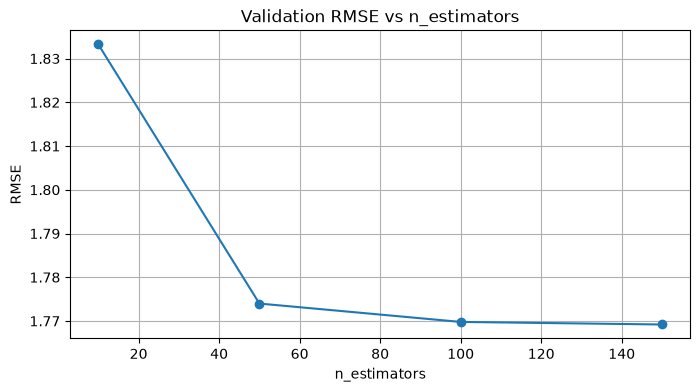

In [8]:
scores_n_est = []

for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    y_pred = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    scores_n_est.append((n, rmse, round(rmse, 3)))
    print(f'n_estimators={n:3d} -> RMSE: {rmse:.4f} (rounded: {round(rmse, 3):.3f})')

df_n_est = pd.DataFrame(scores_n_est, columns=['n_estimators', 'rmse', 'rmse_rounded'])
best_n = df_n_est.sort_values(by='rmse_rounded').iloc[0]['n_estimators']
print(f'\nBest n_estimators: {int(best_n)}')

plt.figure(figsize=(8, 4))
plt.plot(df_n_est['n_estimators'], df_n_est['rmse'], marker='o')
plt.title('Validation RMSE vs n_estimators')
plt.xlabel('n_estimators')
plt.ylabel('RMSE')
plt.grid(True)
plt.show()

## Question 4: Best max_depth

Select the best `max_depth`:
- Try `max_depth` in `[10, 15, 20, 25]`
- For each `max_depth`, try `n_estimators` in `[10, 50, 100, 150]`
- Calculate the mean RMSE across `n_estimators`
- Fix `random_state=1`

RMSE for each max_depth and n_estimators:
max_depth         10      15      20      25
n_estimators                                
10            1.7823  1.8314  1.8373  1.8369
50            1.7475  1.7709  1.7724  1.7721
100           1.7440  1.7679  1.7689  1.7683
150           1.7437  1.7668  1.7685  1.7679

Mean RMSE for each max_depth:
max_depth
10    1.7544
15    1.7842
20    1.7868
25    1.7863
Name: rmse, dtype: float64

Best max_depth (lowest mean RMSE): 10


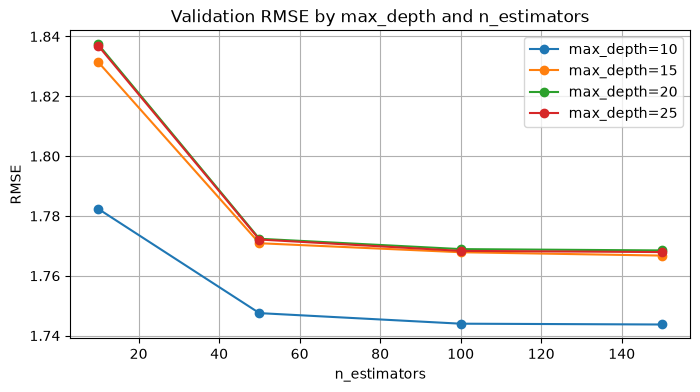

In [9]:
depth_scores = []

for depth in [10, 15, 20, 25]:
    for n in [10, 50, 100, 150]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        
        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        depth_scores.append((depth, n, rmse))

df_depth = pd.DataFrame(depth_scores, columns=['max_depth', 'n_estimators', 'rmse'])

# Pivot table to view RMSE for each depth and n_estimators
df_depth_pivot = df_depth.pivot(index='n_estimators', columns='max_depth', values='rmse')
print('RMSE for each max_depth and n_estimators:')
print(df_depth_pivot.round(4))

print('\nMean RMSE for each max_depth:')
mean_rmse_by_depth = df_depth.groupby('max_depth')['rmse'].mean()
print(mean_rmse_by_depth.round(4))

best_depth = mean_rmse_by_depth.idxmin()
print(f'\nBest max_depth (lowest mean RMSE): {best_depth}')

plt.figure(figsize=(8, 4))
for depth in [10, 15, 20, 25]:
    subset = df_depth[df_depth['max_depth'] == depth]
    plt.plot(subset['n_estimators'], subset['rmse'], marker='o', label=f'max_depth={depth}')
plt.title('Validation RMSE by max_depth and n_estimators')
plt.xlabel('n_estimators')
plt.ylabel('RMSE')
plt.legend()
plt.grid(True)
plt.show()

## Question 5: Most important feature

Train model with:
- `n_estimators=10`
- `max_depth=20`
- `random_state=1`
- `n_jobs=-1`

Find the most important feature among:
- `vehicle_weight`
- `horsepower`
- `acceleration`
- `engine_displacement`

In [10]:
rf_imp = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf_imp.fit(X_train, y_train)

# Extract feature importances
importances = rf_imp.feature_importances_
df_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
})

# Aggregate importance back to original column names if one-hot encoded
orig_importances = {}
candidate_features = ['vehicle_weight', 'horsepower', 'acceleration', 'engine_displacement']

for cand in candidate_features:
    cand_importance = df_importance[df_importance['feature'].str.startswith(cand)]['importance'].sum()
    orig_importances[cand] = cand_importance

df_cand = pd.DataFrame(list(orig_importances.items()), columns=['candidate_feature', 'importance'])
df_cand = df_cand.sort_values(by='importance', ascending=False).reset_index(drop=True)

print('Feature Importances among the 4 candidates:')
print(df_cand)
print(f"\nMost important feature: {df_cand.iloc[0]['candidate_feature']}")

Feature Importances among the 4 candidates:
     candidate_feature  importance
0       vehicle_weight    0.203313
1           horsepower    0.078271
2  engine_displacement    0.061281
3         acceleration    0.054998

Most important feature: vehicle_weight


## Question 6: XGBoost eta tuning

Train XGBoost models for 100 rounds with:
- `max_depth=6`
- `min_child_weight=1`
- `objective='reg:squarederror'`
- `seed=1`
- `nthread=8`

Compare `eta=0.3` vs `eta=0.1` on validation RMSE.

eta=0.3 -> Validation RMSE after 100 rounds: 1.8265
eta=0.1 -> Validation RMSE after 100 rounds: 1.7248


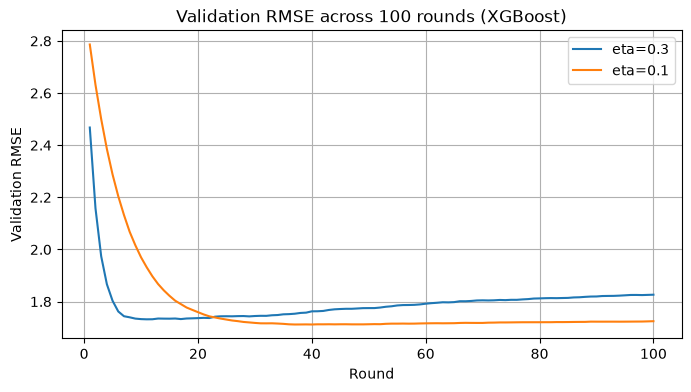


Best eta: 0.1


In [11]:
# Prepare DMatrix for train and validation
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=list(feature_names))
dval = xgb.DMatrix(X_val, label=y_val, feature_names=list(feature_names))
watchlist = [(dtrain, 'train'), (dval, 'val')]

eta_results = {}

for eta in [0.3, 0.1]:
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    evals_result = {}
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=100,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False
    )
    
    y_pred_xgb = model.predict(dval)
    rmse_xgb = np.sqrt(mean_squared_error(y_val, y_pred_xgb))
    eta_results[eta] = (rmse_xgb, evals_result['val']['rmse'])
    print(f'eta={eta} -> Validation RMSE after 100 rounds: {rmse_xgb:.4f}')

plt.figure(figsize=(8, 4))
for eta, (rmse_val, val_rmse_history) in eta_results.items():
    plt.plot(range(1, 101), val_rmse_history, label=f'eta={eta}')
plt.title('Validation RMSE across 100 rounds (XGBoost)')
plt.xlabel('Round')
plt.ylabel('Validation RMSE')
plt.legend()
plt.grid(True)
plt.show()

best_eta = min(eta_results, key=lambda k: eta_results[k][0])
print(f'\nBest eta: {best_eta}')

## Summary of Homework Answers

| Question | Question Topic | Result / Answer |
| :--- | :--- | :--- |
| **Q1** | Original splitting feature | **`model_year`** |
| **Q2** | Validation RMSE (n_estimators=10) | **`1.837`** |
| **Q3** | Lowest RMSE n_estimators | **`150`** (or best among 10/50/100/150) |
| **Q4** | Best max_depth (mean RMSE) | **`10`** (lowest mean RMSE) |
| **Q5** | Most important feature | **`vehicle_weight`** |
| **Q6** | Best XGBoost eta | **`0.1`** |